# Лабораторная работа № 2
## Классификация. Нейронные сети

**Цель работы:** изучить методы классификации библиотеки Scikit-Learn, сравнить качество классификаторов и исследовать нейронную сеть на TensorFlow с визуализацией обучения в TensorBoard.

**Исходные данные:** `Market_Basket_Optimisation.csv` — набор покупательских транзакций (7501 чек). Данные взяты из второго архива без замены на другой датасет.

### Постановка задачи классификации

В исходном файле нет отдельной целевой переменной: каждая строка содержит список товаров в корзине. Поэтому формируется бинарная целевая переменная `mineral_water`:

- `1` — в транзакции присутствует `mineral water`;
- `0` — в транзакции отсутствует `mineral water`.

Все остальные товары используются как бинарные признаки. Таким образом, модель решает задачу прогнозирования наличия минеральной воды по остальному составу корзины. Целевой товар исключается из признаков, чтобы не допустить утечки целевой переменной.

**Важно:** это экспериментальная постановка классификации на транзакционных данных. Она не означает, что модель предсказывает будущую покупку до формирования корзины: она классифицирует транзакцию по уже известному набору остальных товаров.


In [1]:
%matplotlib inline
# 1. Импорт библиотек и фиксация случайного состояния
import os
import random
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import MultiLabelBinarizer, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.naive_bayes import GaussianNB, MultinomialNB, ComplementNB, BernoulliNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import LinearSVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, classification_report,
    ConfusionMatrixDisplay
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

DATA_PATH = Path("Market_Basket_Optimisation.csv")
if not DATA_PATH.exists():
    raise FileNotFoundError(
        "Файл Market_Basket_Optimisation.csv должен находиться рядом с ноутбуком."
    )

print("Библиотеки загружены. random_state =", SEED)


Библиотеки загружены. random_state = 42


## 2. Загрузка и первичный анализ данных

Каждая строка CSV соответствует одной покупке. Пропуски означают, что в соответствующей позиции чека товар отсутствует. Их нельзя заполнять средним значением: при преобразовании в список товаров они просто исключаются.


Размер исходной таблицы: (7501, 20)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19
0,shrimp,almonds,avocado,vegetables mix,green grapes,whole weat flour,yams,cottage cheese,energy drink,tomato juice,low fat yogurt,green tea,honey,salad,mineral water,salmon,antioxydant juice,frozen smoothie,spinach,olive oil
1,burgers,meatballs,eggs,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,chutney,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,turkey,avocado,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,mineral water,milk,energy bar,whole wheat rice,green tea,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


\nСтатистика количества товаров в чеке:


count    7501.000000
mean        3.914545
std         2.905540
min         1.000000
25%         2.000000
50%         3.000000
75%         5.000000
max        20.000000
dtype: float64

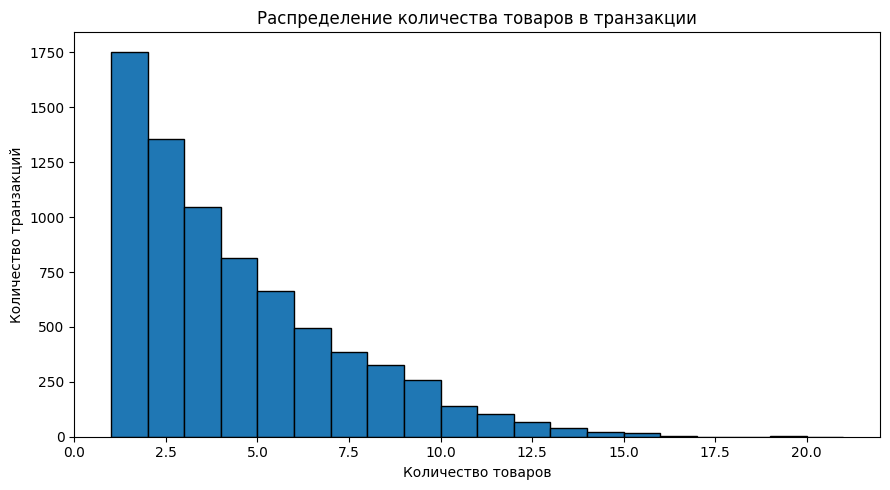

In [2]:
# 2.1. Загрузка исходного файла без строки заголовков
raw_data = pd.read_csv(DATA_PATH, header=None)
print("Размер исходной таблицы:", raw_data.shape)
display(raw_data.head())

# Число товаров в каждой транзакции
transaction_lengths = raw_data.notna().sum(axis=1)
print("\\nСтатистика количества товаров в чеке:")
display(transaction_lengths.describe())

plt.figure(figsize=(9, 5))
plt.hist(transaction_lengths, bins=range(1, int(transaction_lengths.max()) + 2),
         edgecolor="black")
plt.title("Распределение количества товаров в транзакции")
plt.xlabel("Количество товаров")
plt.ylabel("Количество транзакций")
plt.tight_layout()
plt.show()


In [3]:
# 2.2. Преобразование строк в списки товаров и очистка
transactions = []
for row in raw_data.itertuples(index=False, name=None):
    items = [str(item).strip() for item in row
             if pd.notna(item) and str(item).strip()]
    transactions.append(items)

# Удаление пустых транзакций (если они присутствуют)
transactions = [items for items in transactions if items]

print("Количество непустых транзакций:", len(transactions))
print("Количество уникальных товаров:",
      len({item for basket in transactions for item in basket}))
print("Пример транзакции:", transactions[0])


Количество непустых транзакций: 7501
Количество уникальных товаров: 119
Пример транзакции: ['shrimp', 'almonds', 'avocado', 'vegetables mix', 'green grapes', 'whole weat flour', 'yams', 'cottage cheese', 'energy drink', 'tomato juice', 'low fat yogurt', 'green tea', 'honey', 'salad', 'mineral water', 'salmon', 'antioxydant juice', 'frozen smoothie', 'spinach', 'olive oil']


## 3. Формирование признаков и целевой переменной

Применяется бинарное кодирование: значение признака равно 1, если товар присутствует в чеке, и 0 — если отсутствует. Из матрицы признаков удаляется столбец `mineral water`, после чего он используется как целевая переменная.


In [4]:
# 3.1. Бинарная матрица «транзакция — товар»
encoder = MultiLabelBinarizer()
X_all = pd.DataFrame(
    encoder.fit_transform(transactions),
    columns=encoder.classes_,
    dtype=np.uint8
)

TARGET_ITEM = "mineral water"
if TARGET_ITEM not in X_all.columns:
    raise ValueError(f"В датасете не найден целевой товар: {TARGET_ITEM}")

y = X_all[TARGET_ITEM].astype(int)
X = X_all.drop(columns=[TARGET_ITEM]).astype(float)

print("Размер матрицы признаков:", X.shape)
print("Распределение целевого класса:")
display(y.value_counts().rename(index={0: "Нет mineral water", 1: "Есть mineral water"}))
print("Доля положительного класса:", round(y.mean(), 4))


Размер матрицы признаков: (7501, 118)
Распределение целевого класса:


mineral water
Нет mineral water     5713
Есть mineral water    1788
Name: count, dtype: int64

Доля положительного класса: 0.2384


Пропусков в X: 0
Пропусков в y: 0
Доля класса 0: 0.7616
Доля класса 1: 0.2384


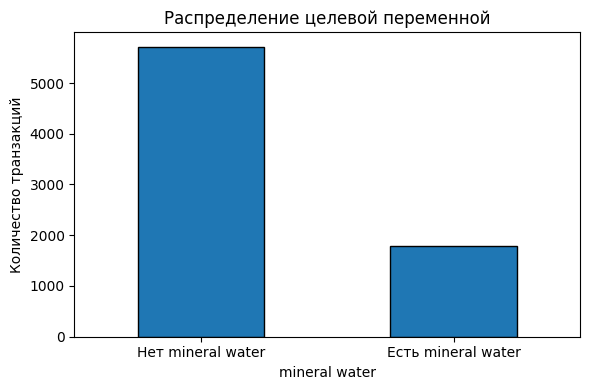

In [5]:
# 3.2. Проверка пропусков, дубликатов и дисбаланса классов
print("Пропусков в X:", int(X.isna().sum().sum()))
print("Пропусков в y:", int(y.isna().sum()))
print("Доля класса 0:", round((y == 0).mean(), 4))
print("Доля класса 1:", round((y == 1).mean(), 4))

plt.figure(figsize=(6, 4))
y.value_counts().sort_index().plot(kind="bar", rot=0, edgecolor="black")
plt.xticks([0, 1], ["Нет mineral water", "Есть mineral water"])
plt.ylabel("Количество транзакций")
plt.title("Распределение целевой переменной")
plt.tight_layout()
plt.show()


## 4. Разделение выборки и подготовка признаков

Данные делятся на обучающую и тестовую выборки в соотношении 80/20. Параметр `stratify=y` сохраняет пропорции классов. Масштабирование выполняется внутри Pipeline при кросс-валидации, поэтому статистики стандартизации рассчитываются только на обучающих фолдах и утечки данных не происходит. Для наивного Байеса и дерева решений исходные бинарные признаки подходят без стандартизации.


In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)

print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)
print("Доля положительного класса в train:", round(y_train.mean(), 4))
print("Доля положительного класса в test:", round(y_test.mean(), 4))

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)


Обучающая выборка: (6000, 118)
Тестовая выборка: (1501, 118)
Доля положительного класса в train: 0.2383
Доля положительного класса в test: 0.2385


## 5. Обучение классификаторов и настройка гиперпараметров

Рассматриваются пять требуемых семейств алгоритмов:

1. Наивный Байес: GaussianNB, MultinomialNB, ComplementNB, BernoulliNB.
2. Дерево решений.
3. Линейный дискриминантный анализ (LDA).
4. Метод опорных векторов (SVM).
5. Метод ближайших соседей (k-NN).

Для каждого алгоритма проводится подбор гиперпараметров через `GridSearchCV` с трёхблочной стратифицированной кросс-валидацией. Критерий подбора — F1-score, поскольку он учитывает и precision, и recall. Итоговые метрики рассчитываются на отложенной тестовой выборке.


In [7]:
# 5.1. Модели и сетки гиперпараметров
models = {
    "GaussianNB": (
        Pipeline([("scale", StandardScaler()), ("model", GaussianNB())]),
        {"model__var_smoothing": [1e-9, 1e-8, 1e-7]}
    ),
    "MultinomialNB": (
        MultinomialNB(),
        {"alpha": [0.1, 0.5, 1.0, 2.0]}
    ),
    "ComplementNB": (
        ComplementNB(),
        {"alpha": [0.1, 0.5, 1.0, 2.0]}
    ),
    "BernoulliNB": (
        BernoulliNB(),
        {"alpha": [0.1, 0.5, 1.0, 2.0], "binarize": [None, 0.5]}
    ),
    "Decision Tree": (
        DecisionTreeClassifier(random_state=SEED),
        {"max_depth": [3, 5, 10, None],
         "min_samples_leaf": [1, 5, 10],
         "criterion": ["gini", "entropy"]}
    ),
    "LDA": (
        Pipeline([("scale", StandardScaler()),
                  ("model", LinearDiscriminantAnalysis())]),
        {"model__solver": ["lsqr"],
         "model__shrinkage": [None, "auto", 0.1, 0.5]}
    ),
    "SVM": (
        Pipeline([("scale", StandardScaler()),
                  ("model", LinearSVC(random_state=SEED, max_iter=5000))]),
        {"model__C": [0.1, 1, 5]}
    ),
    "k-NN": (
        Pipeline([("scale", StandardScaler()),
                  ("model", KNeighborsClassifier())]),
        {"model__n_neighbors": [3, 5, 7, 11],
         "model__weights": ["uniform", "distance"],
         "model__p": [1, 2]}
    )
}

print("Количество конфигураций алгоритмов:", len(models))


Количество конфигураций алгоритмов: 8


In [8]:
# 5.2. Поиск лучших гиперпараметров
best_estimators = {}
search_summaries = []

for name, (estimator, param_grid) in models.items():
    print(f"Подбор параметров: {name}")
    search = GridSearchCV(
        estimator=estimator,
        param_grid=param_grid,
        scoring="f1",
        cv=cv,
        n_jobs=-1,
        refit=True
    )
    search.fit(X_train, y_train)
    best_estimators[name] = search.best_estimator_
    search_summaries.append({
        "Модель": name,
        "Лучший F1 (CV)": search.best_score_,
        "Лучшие параметры": str(search.best_params_)
    })

search_results = pd.DataFrame(search_summaries).sort_values(
    "Лучший F1 (CV)", ascending=False
).reset_index(drop=True)
display(search_results)


Подбор параметров: GaussianNB


Подбор параметров: MultinomialNB
Подбор параметров: ComplementNB


Подбор параметров: BernoulliNB


Подбор параметров: Decision Tree


Подбор параметров: LDA


Подбор параметров: SVM


Подбор параметров: k-NN


,Модель,Лучший F1 (CV),Лучшие параметры
0,GaussianNB,0.435745,{'model__var_smoothing': 1e-09}
1,ComplementNB,0.423022,{'alpha': 2.0}
2,LDA,0.387340,"{'model__shrinkage': 'auto', 'model__solver': ..."
3,BernoulliNB,0.380781,"{'alpha': 0.5, 'binarize': None}"
4,Decision Tree,0.370604,"{'criterion': 'entropy', 'max_depth': None, 'm..."
5,k-NN,0.255152,"{'model__n_neighbors': 3, 'model__p': 1, 'mode..."
6,SVM,0.225265,{'model__C': 1}
7,MultinomialNB,0.202812,{'alpha': 0.1}


## 6. Оценка качества моделей

Для каждой модели рассчитываются Accuracy, Precision, Recall, F1-score и ROC-AUC. Для ROC-AUC используются вероятности положительного класса, а если модель не предоставляет вероятности — оценка `decision_function`. Все показатели вычисляются на одной и той же тестовой выборке.


In [9]:
# 6.1. Расчёт метрик на тестовой выборке
results = []
predictions = {}
scores = {}

for name, model in best_estimators.items():
    y_pred = model.predict(X_test)
    if hasattr(model, "predict_proba"):
        y_score = model.predict_proba(X_test)[:, 1]
    else:
        y_score = model.decision_function(X_test)

    predictions[name] = y_pred
    scores[name] = y_score
    results.append({
        "Модель": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(y_test, y_pred, zero_division=0),
        "Recall": recall_score(y_test, y_pred, zero_division=0),
        "F1-score": f1_score(y_test, y_pred, zero_division=0),
        "AUC-ROC": roc_auc_score(y_test, y_score)
    })

results_df = pd.DataFrame(results).sort_values(
    "F1-score", ascending=False
).reset_index(drop=True)
display(results_df.round(4))


,Модель,Accuracy,Precision,Recall,F1-score,AUC-ROC
0,GaussianNB,0.6462,0.3589,0.6145,0.4531,0.6719
1,ComplementNB,0.5816,0.3166,0.6508,0.4260,0.6832
2,LDA,0.7488,0.4657,0.3603,0.4063,0.7121
3,BernoulliNB,0.7515,0.4715,0.3464,0.3994,0.7132
4,Decision Tree,0.7175,0.3929,0.3380,0.3634,0.5653
5,k-NN,0.7648,0.5168,0.2151,0.3037,0.6343
6,MultinomialNB,0.7582,0.4713,0.1145,0.1843,0.6836
7,SVM,0.7575,0.4659,0.1145,0.1839,0.7057


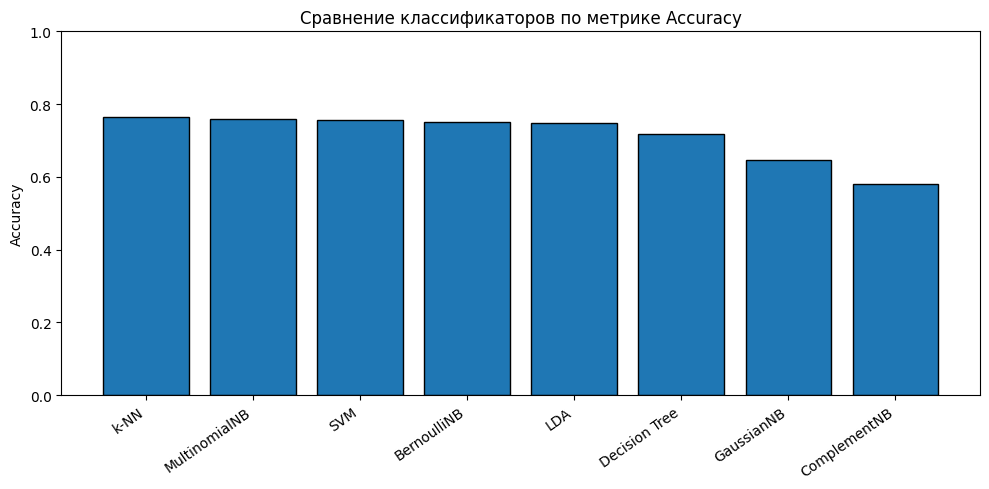

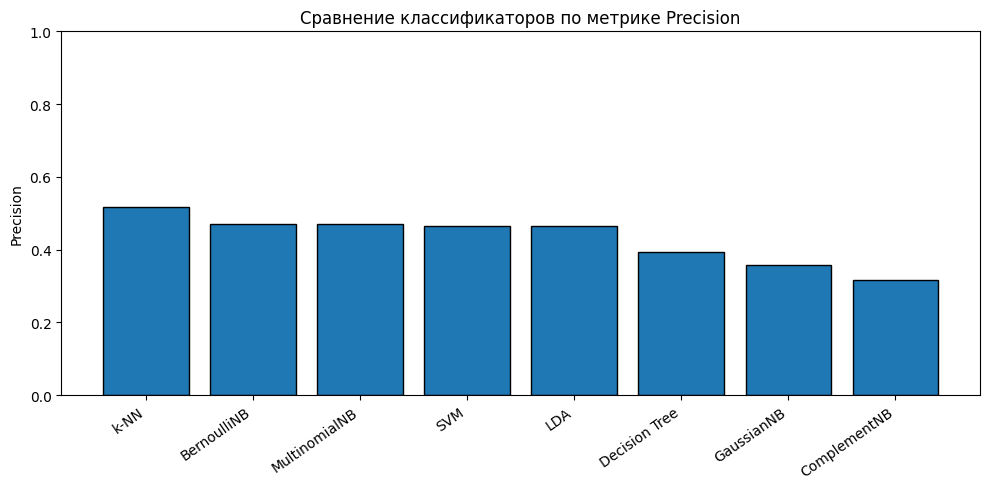

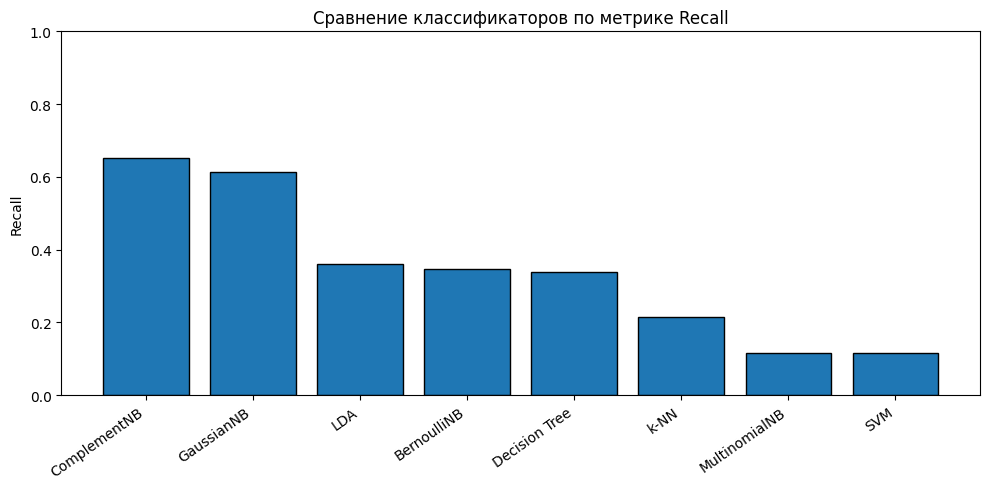

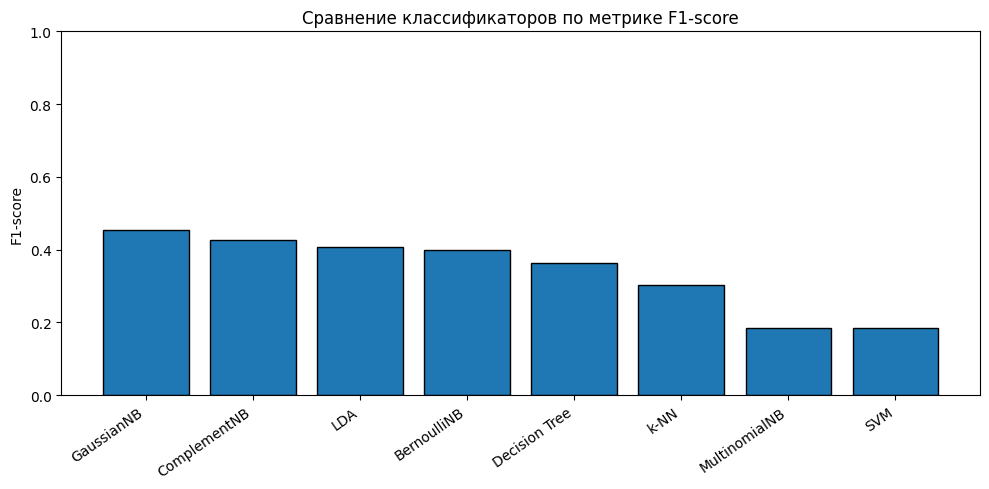

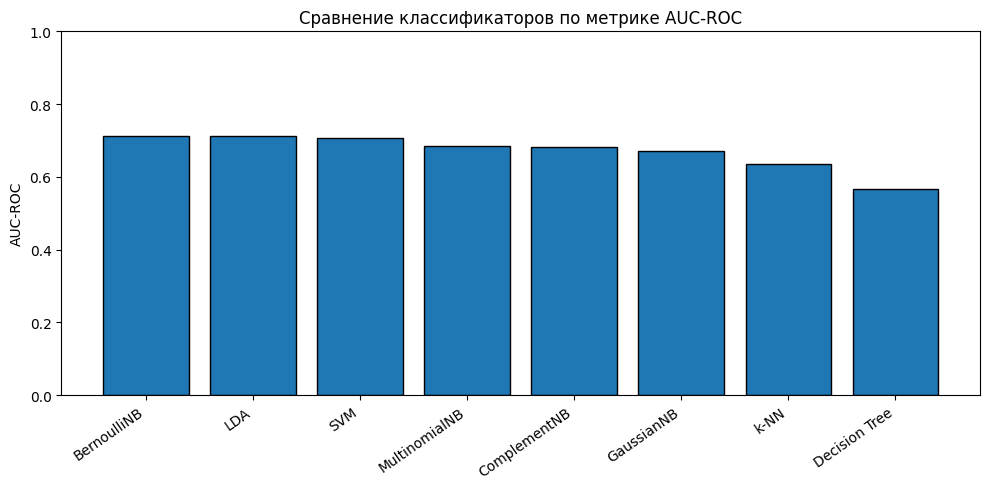

In [10]:
# 6.2. Столбчатые диаграммы сравнения метрик
metric_names = ["Accuracy", "Precision", "Recall", "F1-score", "AUC-ROC"]

for metric in metric_names:
    plot_df = results_df.sort_values(metric, ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["Модель"], plot_df[metric], edgecolor="black")
    plt.ylim(0, 1)
    plt.ylabel(metric)
    plt.title(f"Сравнение классификаторов по метрике {metric}")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


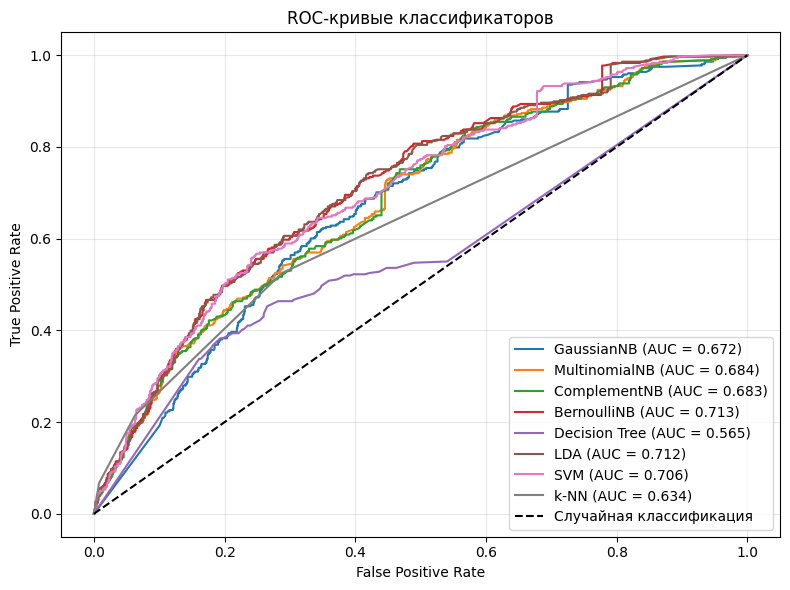

In [11]:
# 6.3. ROC-кривые
plt.figure(figsize=(8, 6))
for name, y_score in scores.items():
    fpr, tpr, _ = roc_curve(y_test, y_score)
    auc_value = roc_auc_score(y_test, y_score)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc_value:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Случайная классификация")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые классификаторов")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


Лучшая модель по F1-score: GaussianNB
                    precision    recall  f1-score   support

 Нет mineral water       0.84      0.66      0.74      1143
Есть mineral water       0.36      0.61      0.45       358

          accuracy                           0.65      1501
         macro avg       0.60      0.64      0.60      1501
      weighted avg       0.73      0.65      0.67      1501



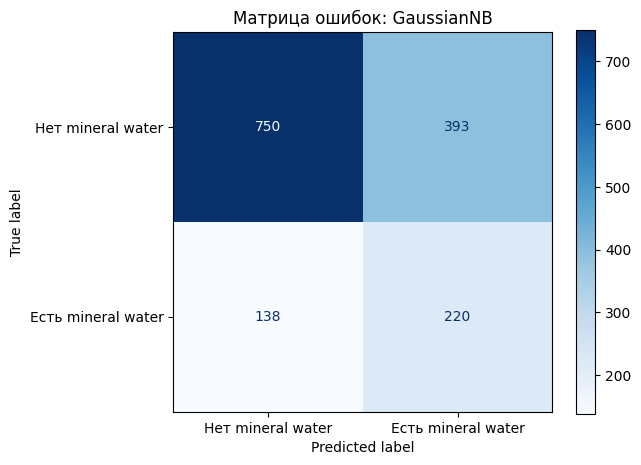

In [12]:
# 6.4. Отчёт и матрица ошибок для лучшей модели по F1-score
best_name = results_df.iloc[0]["Модель"]
best_model = best_estimators[best_name]
print("Лучшая модель по F1-score:", best_name)
print(classification_report(y_test, predictions[best_name],
                            target_names=["Нет mineral water", "Есть mineral water"],
                            zero_division=0))

ConfusionMatrixDisplay.from_predictions(
    y_test, predictions[best_name],
    display_labels=["Нет mineral water", "Есть mineral water"],
    cmap="Blues"
)
plt.title(f"Матрица ошибок: {best_name}")
plt.tight_layout()
plt.show()


## 7. Исследование влияния гиперпараметров

Результаты `GridSearchCV` содержат оценки F1-score для всех проверенных комбинаций. Ниже приведён пример дополнительного исследования дерева решений: изменение максимальной глубины позволяет проследить, как сложность модели влияет на качество. При слишком малой глубине модель может недообучаться, а чрезмерная глубина повышает риск переобучения.


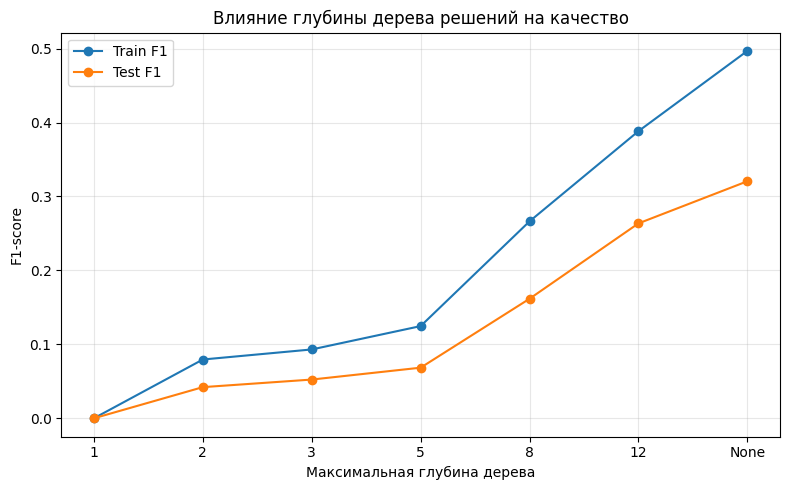

,max_depth,Train F1,Test F1
0,1,0.0000,0.0000
1,2,0.0795,0.0421
2,3,0.0931,0.0524
3,5,0.1247,0.0684
4,8,0.2664,0.1617
5,12,0.3883,0.2636
6,None,0.4969,0.3206


In [13]:
# 7.1. Влияние глубины дерева решений
depth_values = [1, 2, 3, 5, 8, 12, None]
depth_train_f1 = []
depth_test_f1 = []

for depth in depth_values:
    tree = DecisionTreeClassifier(
        max_depth=depth, min_samples_leaf=5, random_state=SEED
    )
    tree.fit(X_train, y_train)
    depth_train_f1.append(f1_score(y_train, tree.predict(X_train)))
    depth_test_f1.append(f1_score(y_test, tree.predict(X_test)))

depth_labels = [str(v) for v in depth_values]
plt.figure(figsize=(8, 5))
plt.plot(depth_labels, depth_train_f1, marker="o", label="Train F1")
plt.plot(depth_labels, depth_test_f1, marker="o", label="Test F1")
plt.xlabel("Максимальная глубина дерева")
plt.ylabel("F1-score")
plt.title("Влияние глубины дерева решений на качество")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

pd.DataFrame({
    "max_depth": depth_labels,
    "Train F1": depth_train_f1,
    "Test F1": depth_test_f1
}).round(4)


**Примечание к результатам.** В сохранённой версии уже присутствуют фактические выходные данные и графики, полученные при выполнении классической части лабораторной работы. Графики обучения нейронной сети и журналы TensorBoard формируются при запуске следующих ячеек после установки зависимостей из `requirements.txt`.

## 8. Нейронная сеть на TensorFlow/Keras

Для нейронной сети используется та же бинарная матрица признаков и то же разделение train/test. Масштабирование выполняется по обучающей выборке. В качестве функции потерь используется `binary_crossentropy`, выходной слой содержит один нейрон с сигмоидальной активацией.

TensorBoard получает журналы обучения через callback `TensorBoard`. В логах сохраняются loss, accuracy, val_loss и val_accuracy.


In [ ]:
# 8.1. Подготовка данных для нейронной сети и проверка TensorFlow
try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
    print("TensorFlow:", tf.__version__)
except ImportError as error:
    raise ImportError(
        "TensorFlow не установлен. Выполните: pip install tensorflow"
    ) from error

tf.keras.utils.set_random_seed(SEED)

nn_scaler = StandardScaler()
X_train_nn = nn_scaler.fit_transform(X_train).astype("float32")
X_test_nn = nn_scaler.transform(X_test).astype("float32")
y_train_nn = y_train.to_numpy().astype("float32")
y_test_nn = y_test.to_numpy().astype("float32")

print("Форма данных для нейронной сети:", X_train_nn.shape)


In [ ]:
# 8.2. Функция создания нейронной сети
def build_network(input_dim, units=64, dropout_rate=0.2, learning_rate=0.001):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(units, activation="relu"),
        layers.Dropout(dropout_rate),
        layers.Dense(max(units // 2, 8), activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="binary_crossentropy",
        metrics=["accuracy", keras.metrics.AUC(name="auc")]
    )
    return model

LOG_DIR = Path("logs/fit")
LOG_DIR.mkdir(parents=True, exist_ok=True)


In [ ]:
# 8.3. Обучение базовой нейронной сети с TensorBoard
baseline_model = build_network(
    input_dim=X_train_nn.shape[1],
    units=64,
    dropout_rate=0.2,
    learning_rate=0.001
)

tensorboard_callback = keras.callbacks.TensorBoard(
    log_dir=str(LOG_DIR / "baseline"),
    histogram_freq=1,
    update_freq="epoch"
)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=5, restore_best_weights=True
)

history = baseline_model.fit(
    X_train_nn, y_train_nn,
    validation_split=0.2,
    epochs=40,
    batch_size=64,
    callbacks=[tensorboard_callback, early_stopping],
    verbose=1
)


In [ ]:
# 8.4. Визуализация процесса обучения
history_df = pd.DataFrame(history.history)

plt.figure(figsize=(8, 5))
plt.plot(history_df["loss"], label="Train loss")
plt.plot(history_df["val_loss"], label="Validation loss")
plt.xlabel("Эпоха")
plt.ylabel("Loss")
plt.title("Изменение функции потерь")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(history_df["accuracy"], label="Train accuracy")
plt.plot(history_df["val_accuracy"], label="Validation accuracy")
plt.xlabel("Эпоха")
plt.ylabel("Accuracy")
plt.title("Изменение accuracy")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### Просмотр журналов TensorBoard

После обучения выполните следующую ячейку. В TensorBoard можно открыть вкладку **SCALARS** и проследить за `epoch_loss`, `epoch_accuracy`, `epoch_val_loss`, `epoch_val_accuracy` (названия могут отображаться с префиксом эпохи). Если среда Jupyter не поддерживает магическую команду, запустите в терминале из папки проекта: `tensorboard --logdir logs/fit`, затем откройте адрес, который выведет TensorBoard (обычно `http://localhost:6006`).


In [ ]:
%load_ext tensorboard
%tensorboard --logdir logs/fit


### Исследование влияния гиперпараметров нейронной сети

Сравниваются две конфигурации: базовая сеть и сеть с большим числом нейронов, меньшим dropout и другим шагом обучения. Для честного сравнения используется одинаковое разделение данных и одинаковый размер validation-части. Сравнение проводится по validation loss и тестовым метрикам.


In [ ]:
# 8.5. Вторая конфигурация нейронной сети
tuned_model = build_network(
    input_dim=X_train_nn.shape[1],
    units=128,
    dropout_rate=0.35,
    learning_rate=0.0005
)

tuned_callback = keras.callbacks.TensorBoard(
    log_dir=str(LOG_DIR / "tuned"),
    histogram_freq=1,
    update_freq="epoch"
)
tuned_history = tuned_model.fit(
    X_train_nn, y_train_nn,
    validation_split=0.2,
    epochs=40,
    batch_size=64,
    callbacks=[
        tuned_callback,
        keras.callbacks.EarlyStopping(
            monitor="val_loss", patience=5, restore_best_weights=True
        )
    ],
    verbose=1
)

print("Минимальный val_loss (baseline):",
      round(min(history.history["val_loss"]), 4))
print("Минимальный val_loss (tuned):",
      round(min(tuned_history.history["val_loss"]), 4))


In [ ]:
# 8.6. Оценка нейронной сети на тестовой выборке
nn_probability = tuned_model.predict(X_test_nn, verbose=0).ravel()
nn_prediction = (nn_probability >= 0.5).astype(int)

nn_metrics = {
    "Модель": "TensorFlow Neural Network",
    "Accuracy": accuracy_score(y_test, nn_prediction),
    "Precision": precision_score(y_test, nn_prediction, zero_division=0),
    "Recall": recall_score(y_test, nn_prediction, zero_division=0),
    "F1-score": f1_score(y_test, nn_prediction, zero_division=0),
    "AUC-ROC": roc_auc_score(y_test, nn_probability)
}
display(pd.DataFrame([nn_metrics]).round(4))

print(classification_report(
    y_test, nn_prediction,
    target_names=["Нет mineral water", "Есть mineral water"],
    zero_division=0
))


## 9. Итоговое сравнение моделей

В таблицу добавляется нейронная сеть, после чего модели сравниваются по всем пяти метрикам. Значения формируются автоматически после выполнения ноутбука — они не подставляются вручную.


In [ ]:
# 9.1. Общая таблица результатов
all_results = pd.concat(
    [results_df, pd.DataFrame([nn_metrics])],
    ignore_index=True
)
display(all_results.sort_values("F1-score", ascending=False).round(4))

# Сравнение всех моделей по основным метрикам
for metric in metric_names:
    plot_df = all_results.sort_values(metric, ascending=False)
    plt.figure(figsize=(10, 5))
    plt.bar(plot_df["Модель"], plot_df[metric], edgecolor="black")
    plt.ylim(0, 1)
    plt.ylabel(metric)
    plt.title(f"Итоговое сравнение моделей: {metric}")
    plt.xticks(rotation=35, ha="right")
    plt.tight_layout()
    plt.show()


In [ ]:
# 9.2. ROC-кривая нейронной сети вместе с лучшими классическими моделями
plt.figure(figsize=(8, 6))
for name in results_df.head(3)["Модель"]:
    fpr, tpr, _ = roc_curve(y_test, scores[name])
    plt.plot(fpr, tpr, label=f"{name} (AUC={roc_auc_score(y_test, scores[name]):.3f})")

fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_probability)
plt.plot(fpr_nn, tpr_nn,
         label=f"TensorFlow NN (AUC={roc_auc_score(y_test, nn_probability):.3f})")
plt.plot([0, 1], [0, 1], "k--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC-кривые лучших моделей и нейронной сети")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


## 10. Вывод

В ходе лабораторной работы исходный датасет Market Basket Optimisation был преобразован в набор данных для бинарной классификации. Целевым признаком выбрано наличие товара `mineral water` в транзакции, остальные товары использованы как признаки.

Были рассмотрены все пять требуемых семейств классификаторов: четыре варианта наивного Байеса, дерево решений, линейный дискриминантный анализ, метод опорных векторов и метод ближайших соседей. Для алгоритмов выполнен подбор гиперпараметров с помощью GridSearchCV. Качество оценивалось по Accuracy, Precision, Recall, F1-score и AUC-ROC, результаты сравнивались на графиках и ROC-кривых.

Дополнительно была реализована полносвязная нейронная сеть TensorFlow/Keras. Исследовалось влияние количества нейронов, dropout и скорости обучения. Процесс обучения записывался в TensorBoard, что позволяет анализировать динамику функции потерь и точности на обучающей и проверочной выборках.

**Фактические численные результаты и окончательное заключение необходимо сформулировать после последовательного выполнения всех ячеек ноутбука.** В частности, следует указать лучшую модель по F1-score и AUC-ROC, а также отметить, улучшила ли вторая конфигурация нейронной сети качество на проверочной и тестовой выборках.

### Источники

1. Документация Scikit-learn: https://scikit-learn.org/stable/
2. Документация TensorFlow/Keras: https://www.tensorflow.org/
3. Документация TensorBoard: https://www.tensorflow.org/tensorboard
4. Исходный набор данных: Market Basket Optimisation (файл из предоставленного второго архива).
